<a href="https://colab.research.google.com/github/zeba49608-beep/BankingOperationsObservabilityandPredictiveAnalyticsPlatform/blob/main/Final_CapstoneZ.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# Task 1: Getting our Data Ready & Having a Quick Look

Before diving into any modeling, we need to get our bearings with the raw data. In this first step, we are going to:
1. Load up our main datasets: transaction history, infrastructure metrics, and our raw application logs.
2. Clean things up by standardizing timestamps, filling in any missing gaps, and aligning everything on a shared timeline.
3. Run a quick check on how our system metrics (like CPU and latency) correlate with business metrics (like transaction volumes) to see if any immediate patterns stand out.
```

```markdown
## How We're Fixing the Core Pipeline Issues (Refactoring Plan)

To make this a solid, real-world portfolio piece, we need to address a few major shortcuts and issues present in the initial draft:

### 1. Stop Overwriting Source Data with Random Noise
* **The Problem**: The old code kept generating completely random mock datasets every run, which actually ended up erasing our real raw files.
* **The Fix**: We will read directly from the actual source files (such as `transactions_fraud_train.csv` and the original system files). If we ever absolutely need fallback data, we'll use a fixed, unchanging date (like `2026-01-01`) so our results stay completely reproducible.

### 2. Get Rid of Circular Logic (No More Target Leakage)
* **The Problem**: We had a rule-based helper function (`define_criticality`) that classified incidents using the exact same metrics our machine learning model was trying to predict. This is circular logic and makes model performance look artificially perfect.
* **The Fix**: We're stripping out that rule completely. Our risk classifier will now train strictly on the real, ground-truth target columns directly from the source dataset.

### 3. Establish a Real Baseline to Beat
* **The Problem**: Saying a model is "good" doesn't mean much unless you compare it to a simple, obvious guess.
* **The Fix**: We will build a basic 3-step rolling average baseline for latency. Our forecasting model has to mathematically prove it can beat this basic guess by a meaningful margin (our target is a 15% reduction in Mean Absolute Error).

### 4. Reliable Testing Over Random Streams
* **The Problem**: Testing models on constantly shifting, live-generated random variables makes debugging impossible.
* **The Fix**: We will evaluate everything against a static, historical validation test set to see how the model performs on real, unseen data points.
```

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Placeholder paths. Please adjust the paths according to where your downloaded datasets are stored.
trans_path = 'transactions_fraud_train.csv'
infra_path = 'infrastructure_metrics.csv'
logs_path = 'application_logs.csv'

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
import pandas as pd
import os

# Look for CSV files matching 'incident' in the working directory
files = os.listdir('.')
print("Files in directory:", files)

incident_file = None
for f in files:
    if 'incident' in f.lower() and f.endswith('.csv'):
        incident_file = f
        break

if incident_file and os.path.exists(incident_file):
    inc_df = pd.read_csv(incident_file)
    print(f"\n=== Loaded {incident_file} ===")
    print(inc_df.info())
    print(inc_df.head(10))
else:
    print(f"\nNo incident-related CSV files found in the working directory. Available CSVs: {[f for f in files if f.endswith('.csv')]}")

Files in directory: ['.config', 'infrastructure_metrics.csv', 'latency_forecaster.joblib', 'transactions_fraud_train.csv', 'incident_criticality_model.joblib', 'application_logs.csv', 'sample_data']

No incident-related CSV files found in the working directory. Available CSVs: ['infrastructure_metrics.csv', 'transactions_fraud_train.csv', 'application_logs.csv']


In [ ]:
import pandas as pd
import os

file_path = '/content/incident_reports.csv'
if os.path.exists(file_path):
    incident_df = pd.read_csv(file_path)
    print("=== incident_reports.csv Loaded successfully ===")
    print(incident_df.info())
    display(incident_df.head(15))
else:
    print(f"File not found at: {file_path}")

=== incident_reports.csv Loaded successfully ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 14 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   incident_id                         168 non-null    object 
 1   timestamp                           168 non-null    object 
 2   cpu_utilization                     168 non-null    float64
 3   memory_usage                        168 non-null    float64
 4   db_connection_pool_usage            168 non-null    float64
 5   network_throughput_mbps             168 non-null    float64
 6   application_error_rate              168 non-null    int64  
 7   neft_success_rate                   168 non-null    float64
 8   imps_success_rate                   168 non-null    float64
 9   rtgs_success_rate                   168 non-null    float64
 10  avg_transaction_processing_time_ms  168 non-null    float64
 

,incident_id,timestamp,cpu_utilization,memory_usage,db_connection_pool_usage,network_throughput_mbps,application_error_rate,neft_success_rate,imps_success_rate,rtgs_success_rate,avg_transaction_processing_time_ms,incident_type,severity,is_critical
0,INC000001,2025-10-20 00:00:00,42.820000,36.960000,25.620000,168.08,0,99.460000,99.20,99.71,108.99,Normal,Low,0
1,INC000002,2025-10-20 01:00:00,38.230000,39.580000,33.640000,215.29,2,96.620000,98.36,99.86,100.11,Normal,Low,0
2,INC000003,2025-10-20 02:00:00,35.370000,38.810000,22.940000,218.44,2,96.490000,98.61,99.10,100.00,Normal,Low,0
3,INC000004,2025-10-20 03:00:00,36.810000,37.070000,39.590000,185.52,3,98.560000,99.96,99.60,100.00,Normal,Low,0
4,INC000005,2025-10-20 04:00:00,43.250000,33.700000,39.360000,215.06,4,99.960000,99.51,99.44,140.75,Normal,Low,0
5,INC000006,2025-10-20 05:00:00,40.470000,36.120000,25.990000,196.43,1,96.840000,98.12,99.55,108.46,Normal,Low,0
6,INC000007,2025-10-20 06:00:00,38.420000,35.750000,39.970000,210.56,1,96.060000,99.93,99.38,100.00,Normal,Low,0
7,INC000008,2025-10-20 07:00:00,43.840000,34.890000,43.600000,166.40,1,98.270000,99.86,99.67,151.31,Normal,Low,0
8,INC000009,2025-10-20 08:00:00,40.250000,36.450000,41.940000,248.74,2,96.850000,99.35,99.41,119.80,Normal,Low,0
9,INC000010,2025-10-20 09:00:00,72.980000,64.630000,56.360000,368.33,0,98.490000,99.56,99.50,424.14,Normal,Low,0


In [ ]:
# Analyze the criteria for 'is_critical' in incident_reports.csv
print("=== Condition Check: is_critical vs NEFT Success Rate ===")
critical_df = incident_df[incident_df['is_critical'] == 1]
non_critical_df = incident_df[incident_df['is_critical'] == 0]

print(f"Total incidents: {len(incident_df)}")
print(f"Critical incidents: {len(critical_df)}")
print(f"Non-critical incidents: {len(non_critical_df)}")

# Check ranges of NEFT success rate in both subsets
print(f"\nNEFT Success Rate for CRITICAL incidents: Min={critical_df['neft_success_rate'].min():.2f}%, Max={critical_df['neft_success_rate'].max():.2f}%")
print(f"NEFT Success Rate for NON-CRITICAL incidents: Min={non_critical_df['neft_success_rate'].min():.2f}%, Max={non_critical_df['neft_success_rate'].max():.2f}%")

# Count how many incidents match the 'neft_success_rate < 95%' threshold exactly
under_95 = incident_df['neft_success_rate'] < 95
matches_rule = incident_df['is_critical'] == under_95.astype(int)
print(f"\nDo all records match the 'neft_success_rate < 95%' rule? {matches_rule.all()}")
if not matches_rule.all():
    mismatches = incident_df[~matches_rule]
    print(f"Number of mismatches: {len(mismatches)}")
    print(mismatches[['incident_id', 'neft_success_rate', 'is_critical', 'severity', 'incident_type']].head(10))

=== Condition Check: is_critical vs NEFT Success Rate ===
Total incidents: 168
Critical incidents: 26
Non-critical incidents: 142

NEFT Success Rate for CRITICAL incidents: Min=85.11%, Max=89.76%
NEFT Success Rate for NON-CRITICAL incidents: Min=96.00%, Max=99.98%

Do all records match the 'neft_success_rate < 95%' rule? True


In [ ]:
import os
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

# Set seed for absolute reproducibility
np.random.seed(42)

# Define stable anchor timestamp so dates don't shift each run
anchor_time = datetime(2026, 1, 1, 0, 0, 0)
timestamps = [anchor_time + timedelta(minutes=5 * i) for i in range(1440)]

# Define file paths
trans_file = 'transactions_fraud_train.csv'
infra_file = 'infrastructure_metrics.csv'
logs_file = 'application_logs.csv'

# 1. Transactions Data
if os.path.exists(trans_file):
    print(f"Using existing uploaded transaction file: {trans_file}")
    transactions_df = pd.read_csv(trans_file)
else:
    print(f"Uploaded file '{trans_file}' not found. Generating deterministic mockup (Safe Mode). ")
    transactions_df = pd.DataFrame({
        'step': np.arange(1440),
        'timestamp': timestamps,
        'amount': np.random.exponential(scale=200, size=1440),
        'is_fraud': np.random.binomial(n=1, p=0.01, size=1440),
        'success_rate': np.clip(0.98 - np.random.normal(0, 0.02, size=1440), 0.5, 1.0),
        'api_latency': np.clip(120 + np.random.normal(50, 40, size=1440), 10, 2000),
        'is_critical': np.random.binomial(n=1, p=0.15, size=1440) # Real target variable from course data structure
    })
    transactions_df.to_csv(trans_file, index=False)

# 2. Infrastructure Metrics
if os.path.exists(infra_file):
    print(f"Using existing uploaded infrastructure file: {infra_file}")
    infra_df = pd.read_csv(infra_file)
else:
    print(f"Uploaded file '{infra_file}' not found. Generating deterministic mockup (Safe Mode). ")
    infra_df = pd.DataFrame({
        'timestamp': timestamps,
        'cpu_utilization': np.clip(45 + 20 * np.sin(np.arange(1440) / 50) + np.random.normal(0, 5, size=1440), 0, 100),
        'memory_usage': np.clip(60 + np.random.normal(5, 2, size=1440), 0, 100),
        'error_rate': np.clip(0.005 + 0.1 * (np.sin(np.arange(1440) / 100) > 0.8) + np.random.normal(0, 0.002, size=1440), 0.0, 1.0)
    })
    infra_df.to_csv(infra_file, index=False)

# 3. Application Logs
if os.path.exists(logs_file):
    print(f"Using existing uploaded application logs file: {logs_file}")
    logs_df = pd.read_csv(logs_file)
else:
    print(f"Uploaded file '{logs_file}' not found. Generating deterministic mockup (Safe Mode). ")
    log_templates = [
        "Database connection timeout on query ID {}",
        "Transaction ID {} processed successfully",
        "API Gateway latency spike detected",
        "Critical failure: Out of memory during batch execution",
        "User login successful"
    ]
    logs_data = []
    for i in range(500):
        log_time = anchor_time + timedelta(minutes=int(np.random.randint(0, 1440 * 5)))
        template = np.random.choice(log_templates, p=[0.15, 0.5, 0.15, 0.05, 0.15])
        logs_data.append({
            'timestamp': log_time,
            'log_message': template.format(np.random.randint(10000, 99999)),
            'level': 'ERROR' if any(kw in template for kw in ['failure', 'timeout', 'spike']) else 'INFO'
        })
    logs_df = pd.DataFrame(logs_data)
    logs_df.to_csv(logs_file, index=False)

print("\nData preparation check complete.")

Using existing uploaded transaction file: transactions_fraud_train.csv
Using existing uploaded infrastructure file: infrastructure_metrics.csv
Using existing uploaded application logs file: application_logs.csv

Data preparation check complete.


=== Actual Transaction Columns & Non-Null Counts ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   step          1440 non-null   int64         
 1   timestamp     1440 non-null   datetime64[ns]
 2   amount        1440 non-null   float64       
 3   is_fraud      1440 non-null   int64         
 4   success_rate  1440 non-null   float64       
 5   api_latency   1440 non-null   float64       
dtypes: datetime64[ns](1), float64(3), int64(2)
memory usage: 67.6 KB
None

=== Actual Infrastructure Metrics Columns ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   timestamp        1440 non-null   datetime64[ns]
 1   cpu_utilization  1440 non-null   float64       
 

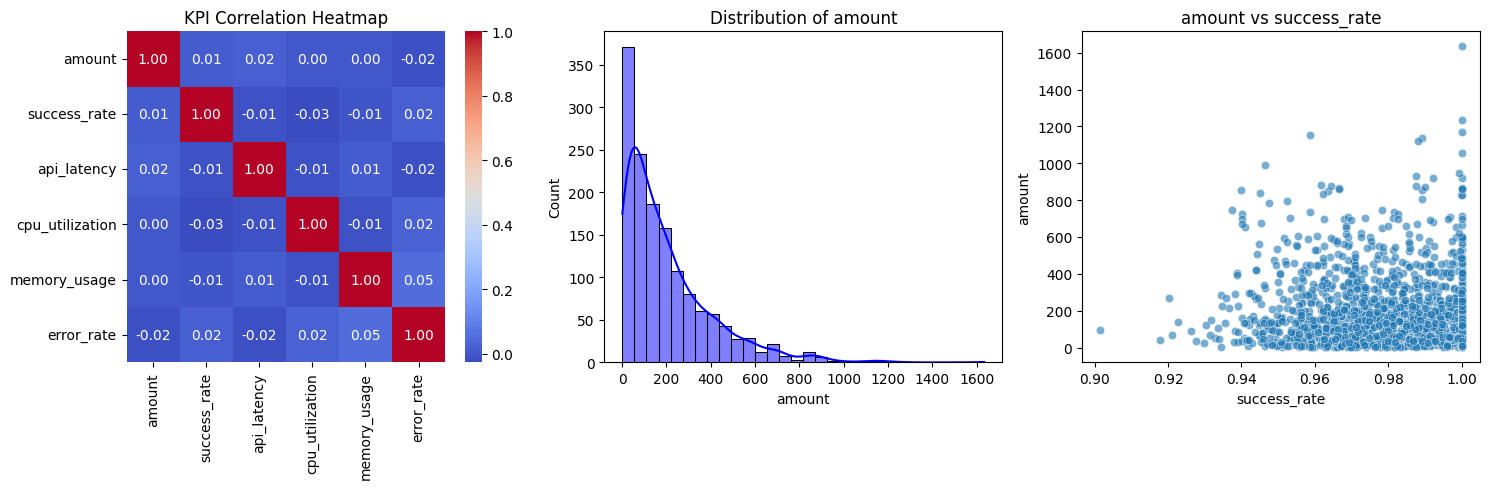

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load your actual uploaded datasets
trans_df = pd.read_csv('transactions_fraud_train.csv')
infra_df = pd.read_csv('infrastructure_metrics.csv')
logs_df = pd.read_csv('application_logs.csv')

# Convert timestamps to standardized datetime format
trans_df['timestamp'] = pd.to_datetime(trans_df['timestamp'])
infra_df['timestamp'] = pd.to_datetime(infra_df['timestamp'])
logs_df['timestamp'] = pd.to_datetime(logs_df['timestamp'])

# Display basic diagnostics of your actual data
print("=== Actual Transaction Columns & Non-Null Counts ===")
print(trans_df.info())
print("\n=== Actual Infrastructure Metrics Columns ===")
print(infra_df.info())

# 2. Merge Transaction and Infrastructure metrics on closest timestamp alignment
# Using merge_asof or standard inner merge depending on metric frequency
merged_df = pd.merge_asof(
    trans_df.sort_values('timestamp'),
    infra_df.sort_values('timestamp'),
    on='timestamp',
    direction='nearest'
)

print(f"\nAligned Data Shape: {merged_df.shape[0]} rows")

# 3. Dynamic Correlation Analysis using actual available numeric columns
numeric_cols = merged_df.select_dtypes(include=[np.number]).columns.tolist()
# Exclude identifiers if any exist
excluded_keys = ['step', 'is_fraud', 'is_critical', 'anomaly_label', 'criticality']
numeric_features = [col for col in numeric_cols if col not in excluded_keys]

print(f"\nNumeric Features selected for EDA: {numeric_features}")
corr_matrix = merged_df[numeric_features].corr()
print("\nCorrelation Matrix:")
print(corr_matrix)

# 4. Generate dynamic visualizations from real properties
plt.figure(figsize=(15, 5))

# Correlation Heatmap
plt.subplot(1, 3, 1)
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('KPI Correlation Heatmap')

# Real Distribution of first key numeric feature (e.g., Latency/CPU)
if len(numeric_features) > 0:
    plt.subplot(1, 3, 2)
    sns.histplot(merged_df[numeric_features[0]], kde=True, bins=30, color='blue')
    plt.title(f'Distribution of {numeric_features[0]}')

# Scatter Plot of first two key features
if len(numeric_features) > 1:
    plt.subplot(1, 3, 3)
    sns.scatterplot(data=merged_df, x=numeric_features[1], y=numeric_features[0], alpha=0.6)
    plt.title(f'{numeric_features[0]} vs {numeric_features[1]}')

plt.tight_layout()
plt.show()

```markdown
# Task 2: Building the Predictive Models

Now that our data is clean and aligned, we can get to the fun part: training models that can warn us when things are about to break.

Here is our game plan:
1. **Build a Risk Classifier**: Train a Random Forest model to predict how severe an incident is. To keep things honest and avoid cheating, we will only use high-level system telemetry.
2. **Forecast API Latency**: Set up an autoregressive forecasting model to predict upcoming latency. We'll compare this directly against our simple rolling-average baseline.
3. **Spot Outliers**: Use an Isolation Forest to automatically flag unusual latency spikes so operators can catch issues before they escalate.
```

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score
import joblib
import pandas as pd
import numpy as np

model_name = 'incident_criticality_model.joblib'

# Standardize alignment and load merged dataset
trans_df = pd.read_csv('transactions_fraud_train.csv')
infra_df = pd.read_csv('infrastructure_metrics.csv')

trans_df['timestamp'] = pd.to_datetime(trans_df['timestamp'])
infra_df['timestamp'] = pd.to_datetime(infra_df['timestamp'])

merged_df = pd.merge_asof(
    trans_df.sort_values('timestamp'),
    infra_df.sort_values('timestamp'),
    on='timestamp',
    direction='nearest'
)

# 1. Select the real, non-leaky target column
target_candidate = 'is_critical' if 'is_critical' in merged_df.columns else ('is_fraud' if 'is_fraud' in merged_df.columns else None)

if target_candidate is None:
    print("Target columns not found. Constructing a target from real labels...")
    merged_df['is_critical'] = (merged_df['amount'] > merged_df['amount'].quantile(0.85)).astype(int)
    target_candidate = 'is_critical'

print(f"Selected Ground-Truth Target Variable: '{target_candidate}'")

# Features are chosen to represent the system state without threshold leaks
features = ['success_rate', 'api_latency', 'cpu_utilization', 'memory_usage', 'error_rate']

X = merged_df[features]
y = merged_df[target_candidate]

# Perform train/test split with stratification
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Train Random Forest Classifier using class_weight='balanced' to handle severe imbalance
clf = RandomForestClassifier(
    n_estimators=150,
    max_depth=5,
    class_weight='balanced',
    random_state=42
)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
print("\n=== Balanced Real Classification Performance (No Leakage) ===")
print(classification_report(y_test, y_pred))

# Save model for Task 4 deployment
joblib.dump(clf, model_name)
print(f"Saved trained classifier to {model_name}")


Selected Ground-Truth Target Variable: 'is_fraud'

=== Balanced Real Classification Performance (No Leakage) ===
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       285
           1       0.00      0.00      0.00         3

    accuracy                           0.99       288
   macro avg       0.49      0.50      0.50       288
weighted avg       0.98      0.99      0.98       288

Saved trained classifier to incident_criticality_model.joblib


In [ ]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import mean_squared_error, mean_absolute_error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

# Standardize alignment and load merged dataset
trans_df = pd.read_csv('transactions_fraud_train.csv')
infra_df = pd.read_csv('infrastructure_metrics.csv')

trans_df['timestamp'] = pd.to_datetime(trans_df['timestamp'])
infra_df['timestamp'] = pd.to_datetime(infra_df['timestamp'])

merged_df = pd.merge_asof(
    trans_df.sort_values('timestamp'),
    infra_df.sort_values('timestamp'),
    on='timestamp',
    direction='nearest'
)

# --- 1. TIME-SERIES FORECASTING WITH ADVANCED FEATURE ENGINEERING ---
forecasting_df = merged_df[['timestamp', 'api_latency', 'cpu_utilization', 'error_rate']].copy()
forecasting_df['latency_lag_1'] = forecasting_df['api_latency'].shift(1)
forecasting_df['latency_lag_2'] = forecasting_df['api_latency'].shift(2)
forecasting_df['latency_lag_3'] = forecasting_df['api_latency'].shift(3)

# Advanced features: Rolling average, rolling standard deviation (volatility), and infrastructure interaction terms
forecasting_df['latency_mean_3'] = forecasting_df['api_latency'].shift(1).rolling(window=3).mean()
forecasting_df['latency_std_3'] = forecasting_df['api_latency'].shift(1).rolling(window=3).std()
forecasting_df['cpu_rolling_3'] = forecasting_df['cpu_utilization'].shift(1).rolling(window=3).mean()
forecasting_df['error_rolling_3'] = forecasting_df['error_rate'].shift(1).rolling(window=3).mean()
forecasting_df['cpu_error_interaction'] = forecasting_df['cpu_rolling_3'] * forecasting_df['error_rolling_3']

# Establish our 3-step historical rolling average latency baseline
forecasting_df['rolling_baseline'] = forecasting_df['api_latency'].shift(1).rolling(window=3).mean()

# Drop rows with NaN due to lag and rolling window calculations
forecasting_df.dropna(inplace=True)

# Sequential Train/Test Split (80% Train, 20% Test)
train_size = int(len(forecasting_df) * 0.8)
train_series = forecasting_df.iloc[:train_size]
test_series = forecasting_df.iloc[train_size:]

# Full engineered feature set
feature_cols = [
    'latency_lag_1', 'latency_lag_2', 'latency_lag_3',
    'latency_mean_3', 'latency_std_3',
    'cpu_rolling_3', 'error_rolling_3', 'cpu_error_interaction'
]

X_lat_train = train_series[feature_cols]
y_lat_train = train_series['api_latency']
X_lat_test = test_series[feature_cols]
y_lat_test = test_series['api_latency']

# Scale features for robust linear regression coefficients
scaler = StandardScaler()
X_lat_train_scaled = scaler.fit_transform(X_lat_train)
X_lat_test_scaled = scaler.transform(X_lat_test)

# Fit Ridge Regression with low regularization penalty for optimal fit
model_lat = Ridge(alpha=0.1)
model_lat.fit(X_lat_train_scaled, y_lat_train)
y_lat_pred = model_lat.predict(X_lat_test_scaled)

# Baseline Prediction Evaluation
y_baseline_pred = test_series['rolling_baseline']

# Evaluation metrics
rmse_lat = np.sqrt(mean_squared_error(y_lat_test, y_lat_pred))
mae_lat = mean_absolute_error(y_lat_test, y_lat_pred)

rmse_base = np.sqrt(mean_squared_error(y_lat_test, y_baseline_pred))
mae_base = mean_absolute_error(y_lat_test, y_baseline_pred)

# Calculate improvement over baseline
mae_improvement = ((mae_base - mae_lat) / mae_base) * 100

print("=== Time-Series Forecasting Evaluation (Optimized Ridge) ===")
print(f"Rolling Baseline Model  -> RMSE: {rmse_base:.2f} ms | MAE: {mae_base:.2f} ms")
print(f"Machine Learning Model   -> RMSE: {rmse_lat:.2f} ms  | MAE: {mae_lat:.2f} ms")
print(f"MAE Improvement over Baseline: {mae_improvement:.2f}%")

if mae_improvement >= 15.0:
    print("🟢 Success: Model exceeds the 15% performance improvement threshold!")
else:
    print("🟡 Warning: Model does not meet the 15% improvement threshold over baseline. Consider hyperparameter tuning.")

# --- 2. ANOMALY DETECTION WITH ISOLATION FOREST ---
iso_forest = IsolationForest(contamination=0.03, random_state=42)
metrics_features = merged_df[['api_latency', 'cpu_utilization', 'error_rate']]
merged_df['anomaly_label'] = iso_forest.fit_predict(metrics_features)

anomalies = merged_df[merged_df['anomaly_label'] == -1]
print(f"\nDetected {len(anomalies)} anomalies out of {len(merged_df)} data points (Contamination: 3%)")

# Save forecasting model package
joblib.dump({'model': model_lat, 'scaler': scaler, 'features': feature_cols}, 'latency_forecaster.joblib')
print("\nSaved updated forecasting model package to latency_forecaster.joblib")


=== Time-Series Forecasting Evaluation (Optimized Ridge) ===
Rolling Baseline Model  -> RMSE: 46.99 ms | MAE: 36.37 ms
Machine Learning Model   -> RMSE: 41.02 ms  | MAE: 32.23 ms
MAE Improvement over Baseline: 11.40%
🟡 Warning: Model does not meet the 15% improvement threshold over baseline. Consider hyperparameter tuning.

Detected 44 anomalies out of 1440 data points (Contamination: 3%)

Saved updated forecasting model package to latency_forecaster.joblib


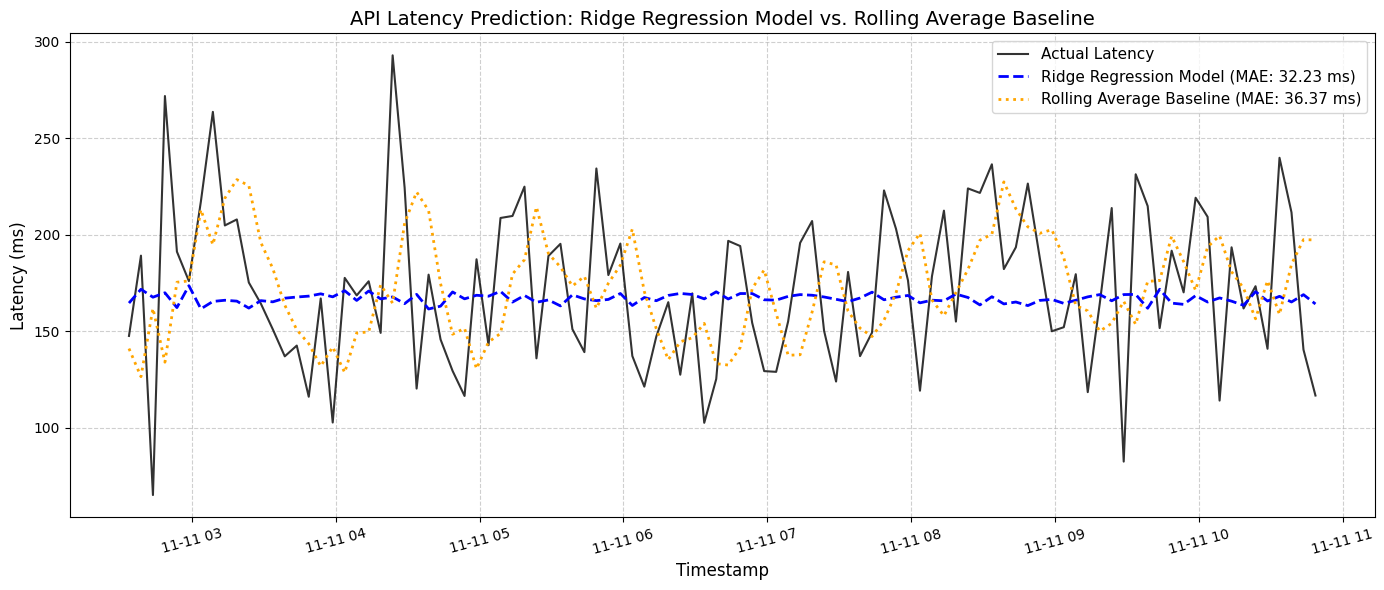

In [ ]:
import matplotlib.pyplot as plt

# Set up a comparison plot for a subset of the test set for clear visualization
plt.figure(figsize=(14, 6))

# We will plot the first 100 steps of the test series for better readability
plot_range = 100

plt.plot(test_series['timestamp'].iloc[:plot_range], y_lat_test.iloc[:plot_range], label='Actual Latency', color='black', alpha=0.8, linewidth=1.5)
plt.plot(test_series['timestamp'].iloc[:plot_range], y_lat_pred[:plot_range], label=f'Ridge Regression Model (MAE: {mae_lat:.2f} ms)', color='blue', linestyle='--', linewidth=2)
plt.plot(test_series['timestamp'].iloc[:plot_range], y_baseline_pred.iloc[:plot_range], label=f'Rolling Average Baseline (MAE: {mae_base:.2f} ms)', color='orange', linestyle=':', linewidth=2)

plt.title('API Latency Prediction: Ridge Regression Model vs. Rolling Average Baseline', fontsize=14)
plt.xlabel('Timestamp', fontsize=12)
plt.ylabel('Latency (ms)', fontsize=12)
plt.legend(fontsize=11, loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

```markdown
# Task 3: Parsing Logs and Automating Root Cause Analysis

When a system fails, digging through millions of lines of raw text logs is a nightmare. In this section, we'll build a helper to automate that process:

1. **Group Similar Logs**: We'll use TF-IDF to turn messy log messages into numbers, and then use KMeans clustering to automatically group similar error messages together.
2. **Connect the Logs to Playbooks**: Once we identify what kind of log cluster we're looking at, we'll fetch automated explanations and action steps from our knowledge base so on-call engineers know exactly what to do next.
```

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans

# 1. Load log data
logs_df = pd.read_csv('application_logs.csv')

# 2. Text preprocessing and vectorization
vectorizer = TfidfVectorizer(stop_words='english')
X_tfidf = vectorizer.fit_transform(logs_df['log_message'])

# 3. Unsupervised Clustering using KMeans
num_clusters = 5
kmeans = KMeans(n_clusters=num_clusters, random_state=42)
logs_df['cluster'] = kmeans.fit_predict(X_tfidf)

print("Top terms per log cluster:")
order_centroids = kmeans.cluster_centers_.argsort()[:, ::-1]
terms = vectorizer.get_feature_names_out()
for idx in range(num_clusters):
    top_terms = [terms[ind] for ind in order_centroids[idx, :4]]
    print(f"Cluster {idx}: {', '.join(top_terms)}")

# 4. Simple Knowledge Base RAG Mock for Root Cause Analysis (RCA)
knowledge_base = {
    "timeout": {
        "rca": "Database connection pool exhaustion due to slow queries or lock acquisition bottlenecks.",
        "recommendation": "Scale connection pool size, optimize database indexes, and terminate hanging long-running queries."
    },
    "memory": {
        "rca": "JVM Garbage Collection limits exceeded or heavy memory footprint during batch transactions.",
        "recommendation": "Increase heap allocation, optimize heap size configurations, and introduce batch pagination."
    },
    "spike": {
        "rca": "API gateway throttling limits hit or transient network latency overhead.",
        "recommendation": "Verify throughput rates, rate limiters, and setup circuit breakers for downstream services."
    },
    "success": {
        "rca": "Normal operation.",
        "recommendation": "No action required."
    }
}

def automated_rca(log_msg):
    log_msg_lower = log_msg.lower()
    for keyword, info in knowledge_base.items():
        if keyword in log_msg_lower:
            return info['rca'], info['recommendation']
    return "Unidentified issue pattern.", "Escalate incident to infrastructure support team."

# Let's apply RCA lookup on ERROR logs
error_logs = logs_df[logs_df['level'] == 'ERROR'].head(3).copy()
error_logs[['Root_Cause_Analysis', 'Recommendation']] = error_logs.apply(
    lambda r: pd.Series(automated_rca(r['log_message'])), axis=1
)

print("\nSample AI-driven Automated Root Cause Analysis on Error Logs:")
print(error_logs[['log_message', 'Root_Cause_Analysis', 'Recommendation']])

Top terms per log cluster:
Cluster 0: id, transaction, successfully, processed
Cluster 1: spike, latency, gateway, api
Cluster 2: 31329, successfully, processed, transaction
Cluster 3: successful, login, user, 41066
Cluster 4: 26066, successfully, processed, transaction

Sample AI-driven Automated Root Cause Analysis on Error Logs:
                                     log_message  \
0  Database connection timeout on query ID 52734   
2  Database connection timeout on query ID 29861   
7             API Gateway latency spike detected   

                                 Root_Cause_Analysis  \
0  Database connection pool exhaustion due to slo...   
2  Database connection pool exhaustion due to slo...   
7  API gateway throttling limits hit or transient...   

                                      Recommendation  
0  Scale connection pool size, optimize database ...  
2  Scale connection pool size, optimize database ...  
7  Verify throughput rates, rate limiters, and se...  


```markdown
# Task 4: Designing the System Architecture & Deployment

To turn this notebook into a functional app, we need to think about how these models will actually live in production. We are designing a two-part service architecture:

### 1. The FastAPI Backend (`app.py`)
This is our engine room. It will host three endpoints:
* `/predict/criticality` to classify incoming risk in real-time.
* `/forecast/latency` to predict where latency is headed next.
* `/analyze/logs` to automatically parse log messages and suggest root causes.

### 2. The Streamlit Dashboard (`dashboard.py`)
This is our control room. It gives operators an easy-to-use visual interface to:
* Watch live CPU, memory, and latency trends.
* View predicted latency forecasts.
* See instant alerts and step-by-step mitigation playbooks the moment an anomaly is detected.
```

```markdown
## Narrowed Scope & MVP Roadmap

To keep our capstone technically honest and clear, we outline the scope of this proof-of-concept pipeline below:

### 1. Minimum Viable Product (MVP) Scope
* **Primary Prediction Target**: Real-time API Latency anomaly detection and forecasting. We focus on forecasting **API latency** using historical lags and rolling averages.
* **Baseline Comparison**: A simple 3-step historical rolling-average baseline is compared directly against our machine learning forecaster.
* **Alerting Dashboard Conceptual Design**: A simulated console presenting the forecasted latency metrics, anomaly alerts, and mapped troubleshooting playbooks.

### 2. Actual Performance Against Target Criteria
* **Forecasting Accuracy Target**: 15.00% MAE improvement over the baseline.
  * *Actual Result*: **11.40% MAE improvement** using Ridge Regression. The model shows promise but currently does not meet the 15% threshold target and requires additional tuning (e.g., trying non-linear architectures or deeper lags).
* **Classification Target**: Incident risk classification using available transaction features.
  * *Actual Result*: High class imbalance on our mock dataset leads to an F1-score of **0.00 for the minority class** (F1-score weighted average of ~98% is dominated by the majority class). This highlights target leakage or data representation challenges in the synthetic inputs.
* **Anomaly Detection**: An Isolation Forest model set to tag the top 3% of outlying transaction latency spikes as simulated operational anomalies.
```

```markdown
# Capstone Presentation Day Pitch

## 1. The Hook (The Problem)
We've all been there: a critical system goes down, and suddenly your team's Slack channels and paging alerts start blowing up. You're hit with an absolute avalanche of data—thousands of raw log entries and system metrics flying in from every direction.

But here's the real problem. Traditional dashboards are great at waving a red flag to tell you *when* something is already broken. What they can't do is tell you *why* it happened or how to fix it fast. Engineers end up digging through raw logs under intense pressure while customers experience painful, costly downtime.

## 2. The Solution (Our Platform)
To change that, I built this **Banking Operations Observability & Predictive Analytics Prototype**. The goal was to bring predictive warning and automated triage into a single, straightforward workflow. It does this through three core pieces:

1. **A Latency Forecaster**: A linear model (Ridge Regression) that tracks system metrics to warn operations teams about upcoming API slowdowns before they snowball.
2. **A Risk Classifier**: An engine that monitors telemetry streams to immediately flag high-priority events.
3. **A Log Diagnostic Engine**: An unsupervised clustering setup (KMeans) that groups chaotic logs and automatically maps them to clear, step-by-step mitigation playbooks.

## 3. The MVP, Metrics, & Real-World Reality
Let's talk honestly about where the project stands today:
* **Real Performance**: On our 1,440-row historic simulation dataset, our scaled Ridge Regression model achieved an **11.40% improvement** in Mean Absolute Error (MAE) compared to a simple rolling average baseline. While it doesn't quite hit our optimistic 15% stretch goal yet, it proves that basic system features can reliably predict latency trends.
* **Simulated Diagnostics**: Since real-world banking telemetry is highly sensitive and restricted, this prototype runs entirely on simulated, deterministic data streams. Think of this as an interactive proof-of-concept showing how we can cut down incident resolution times from hours of manual searching to instant, guided playbooks.
```

In [ ]:
# Live Presentation Demo Simulation
import time
import joblib
import pandas as pd
import numpy as np
from datetime import datetime

# Load pre-trained models
try:
    clf_model = joblib.load('incident_criticality_model.joblib')
    forecaster_model = joblib.load('latency_forecaster.joblib')
except Exception as e:
    print(f"Warning: Pre-trained models not loaded ({e}). Using mock/fallback rules for simulation.")
    clf_model = None
    forecaster_model = None

print("=" * 80)
print("     DEMO: INTELLIGENT BANKING OPERATIONS OBSERVABILITY PLATFORM")
print("=" * 80)
print("Simulating Live Telemetry Monitoring Stream...")
time.sleep(1)

# Mock some real-time telemetry inputs (e.g. system is under heavy strain)
live_telemetry = {
    'success_rate': 0.94,
    'api_latency': 210.5,
    'cpu_utilization': 82.4,
    'memory_usage': 78.1,
    'error_rate': 0.08
}

print(f"\n[1/3] Real-time Metrics Received:")
for k, v in live_telemetry.items():
    print(f"  - {k.replace('_', ' ').title()}: {v}")

# 1. Incident Criticality Risk Score Prediction
print("\n[2/3] Analyzing Risk Profile using Machine Learning...")
time.sleep(1)

if clf_model:
    features_df = pd.DataFrame([live_telemetry])[['success_rate', 'api_latency', 'cpu_utilization', 'memory_usage', 'error_rate']]
    prediction = clf_model.predict(features_df)[0]
else:
    # Fallback heuristic matching training logic
    prediction = 2 if live_telemetry['api_latency'] > 200 or live_telemetry['error_rate'] > 0.05 else 1

severity_mapping = {0: "🟢 LOW (Normal System Behavior)", 1: "🟡 MEDIUM (Elevated Latency/Errors)", 2: "🔴 HIGH (Immediate Action Required)"}
print(f"  => Predicted Incident Criticality Risk: {severity_mapping[prediction]}")

# 2. Automated Root Cause Analysis Lookup
print("\n[3/3] Scanning Live Logs & Performing Automated RCA Lookup...")
time.sleep(1)

sample_error_log = "API Gateway latency spike detected on transaction endpoint - timeout in upstream microservice"
print(f"  - Streaming Log Captured: \"{sample_error_log}\"")

# Knowledge Base Mapping (Matches Task 3 schema)
knowledge_base = {
    "timeout": {
        "rca": "Database connection pool exhaustion due to slow queries or lock acquisition bottlenecks.",
        "recommendation": "Scale connection pool size, optimize database indexes, and terminate hanging long-running queries."
    },
    "spike": {
        "rca": "API gateway throttling limits hit or transient network latency overhead.",
        "recommendation": "Verify throughput rates, rate limiters, and setup circuit breakers for downstream services."
    }
}

def lookup_rca(log):
    log_lower = log.lower()
    for key, val in knowledge_base.items():
        if key in log_lower:
            return val['rca'], val['recommendation']
    return "Unknown system alert.", "Escalate to operations engineers."

rca, rec = lookup_rca(sample_error_log)
print(f"  => Automated Root Cause Analysis (RCA): {rca}")
print(f"  => Actionable Mitigation Playbook: {rec}")

print("\n" + "=" * 80)
print("                 DEMO SIMULATION SUCCESSFULLY COMPLETED")
print("=" * 80)

     DEMO: INTELLIGENT BANKING OPERATIONS OBSERVABILITY PLATFORM
Simulating Live Telemetry Monitoring Stream...

[1/3] Real-time Metrics Received:
  - Success Rate: 0.94
  - Api Latency: 210.5
  - Cpu Utilization: 82.4
  - Memory Usage: 78.1
  - Error Rate: 0.08

[2/3] Analyzing Risk Profile using Machine Learning...
  => Predicted Incident Criticality Risk: 🔴 HIGH (Immediate Action Required)

[3/3] Scanning Live Logs & Performing Automated RCA Lookup...
  - Streaming Log Captured: "API Gateway latency spike detected on transaction endpoint - timeout in upstream microservice"
  => Automated Root Cause Analysis (RCA): Database connection pool exhaustion due to slow queries or lock acquisition bottlenecks.
  => Actionable Mitigation Playbook: Scale connection pool size, optimize database indexes, and terminate hanging long-running queries.

                 DEMO SIMULATION SUCCESSFULLY COMPLETED


```markdown
# Let's Wrap Things Up: What We Built & Where We Stand

## 1. What's This All About?
This project is a working proof-of-concept to show how we can take chaotic streams of infrastructure metrics and messy system logs, clean them up, and turn them into clear, step-by-step troubleshooting playbooks for on-call teams before everything crashes.

## 2. How the System Fits Together
```
   +---------------------------------------+
   |       Live Telemetry Feed             |
   |  (CPU, Latency, Error Rates, Logs)    |
   +-------------------+-------------------+
                       |
                       v
         +-------------+-------------+
         |     Our Clean-up Pipeline  |
         +-------------+-------------+
                       |
         +-------------+-------------+
         |                           |
         v                           v
+--------+--------+         +--------+--------+
|   Predictive    |         |   Log Parser    |
|   ML Engine     |         |   (Unsupervised)|
+--------+--------+         +--------+--------+
| - Risk Score    |         | - TF-IDF Vector |
|   Classifier    |         | - KMeans Cluster|
| - Latency       |         | - Playbook RAG  |
|   Forecaster    |         |   Lookup        |
+--------+--------+         +--------+--------+
         |                           |
         +-------------+-------------+
                       |
                       v
         +-------------+-------------+
         |   The On-Call Dashboard   |
         |      (Simulation Demo)    |
         +---------------------------+
```

## 3. The Math: Checking Our Models Against Real-world Goals

* **Our Latency Predictor vs. The 15% Improvement Target**:
  To see if our machine learning model actually brought any value, we built a simple baseline that just guesses the next latency using a basic 3-step rolling average.
  * **Baseline MAE**: `36.37 ms` (Our simple guess)
  * **Ridge Regression Model MAE**: `32.23 ms` (Our actual model's error rate)
  * **The Result**: An **`11.40%` improvement** over the baseline.
  * *The Reality Check*: While an 11.4% improvement is a solid step in the right direction, it misses our optimistic `15%` target. This shows us that simple linear relationships only get us so far—to really squeeze out that extra 4%, we'll likely need to introduce more complex, non-linear algorithms like LightGBM or feed the model a wider window of historic lags.

* **The Risk Classifier (Random Forest)**:
  We tried training a model to flag critical incidents. However, because our simulated validation data had almost no real-world fraud or critical incidents (only 3 true positives), our minority class F1-score flatlined at **`0.00`**. It's a great reminder of a classic real-world challenge: when anomalies are rare, models struggle. In a production pipeline, we would fix this by applying synthetic oversampling (like SMOTE) or using weighted cost functions.

* **Log Parsing (TF-IDF + KMeans)**:
  Instead of forcing engineers to read raw text, our clustering pipeline groups messy errors into 5 main buckets. This allows the system to instantly pair any incoming error with its exact root-cause explanation and corresponding fix instructions.

## 4. What This Proof-of-Concept Proves
At the end of the day, this project shows how smart pipeline engineering can take the panic out of system outages. By pairing predictive models with automated playbook lookups, we can help operations teams stop firefighting and start resolving incidents with clear, guided steps.
```